# Forecasting Mexico City's Air Quality Scenario One Hour Ahead (2020–2025)

**Goal.** Predict which atmospheric scenario (*Clean air*, *Moderate urban*, *Ozone peak* or
*High pollution*) each monitoring station will be in during the **next hour**, using the
pollutant readings of the last 24 hours.

This notebook extends the 2025 clustering analysis (`01_clustering_2025.ipynb`) to six years of
hourly data and turns it into a supervised problem:

1. **K-Means** (k = 4, as in notebook 01) labels every station-hour with a scenario.
2. A stacked **LSTM** network reads 24-hour windows and classifies the scenario at t + 1.

**Evaluation design.** The data is split **by time**, and every step that learns from the data
(outlier bounds, imputation, scaling, K-Means and the network) is fitted on the training period
only:

| Split | Period | Used for |
|---|---|---|
| Train | 2020–2023 | Fitting every preprocessing step and the models |
| Validation | 2024 | Early stopping and model selection |
| Test | 2025 | Final, untouched evaluation |

The LSTM is compared with simple **baselines**, starting with *persistence* (the next hour has
the same scenario as the current one), which notebook 01 showed to be strong.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf

from cdmx_air import cleaning, clustering
from cdmx_air.clustering import SCENARIO_ORDER
from cdmx_air.config import MODEL_FEATURES, POLLUTANTS, RANDOM_STATE, SELECTED_STATIONS, UNITS
from cdmx_air.data import load_years
from cdmx_air.plots import save_fig, set_style
from cdmx_air.sequences import make_sequences

warnings.filterwarnings("ignore", category=FutureWarning)
# MICE stops at max_iter=10 before its tolerance is met; the imputed values are stable enough.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
set_style()
pd.set_option("display.precision", 3)

LOOK_BACK = 24  # hours of history per sample, justified by the autocorrelation analysis below
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 1. Load the data (2020–2025)

In [2]:
raw = load_years(range(2020, 2026))
df = raw.loc[raw["station"].isin(SELECTED_STATIONS)].drop(columns="PMCO")

# SEDEMA's hour 24 belongs to the previous day, so the year is taken from (datetime - 1 h).
year = (df["datetime"] - pd.Timedelta(hours=1)).dt.year
df["split"] = np.select([year <= 2023, year == 2024], ["train", "validation"], default="test")

print(f"{len(df):,} station-hours from {df['datetime'].min():%Y-%m-%d} to {df['datetime'].max():%Y-%m-%d}")
df.groupby("split", sort=False).agg(
    start=("datetime", "min"), end=("datetime", "max"), station_hours=("datetime", "size")
)

368,242 station-hours from 2020-01-01 to 2026-01-01


,start,end,station_hours
split,,,
train,2020-01-01 01:00:00,2024-01-01,245448
validation,2024-01-01 01:00:00,2025-01-01,61474
test,2025-01-01 01:00:00,2026-01-01,61320


In [3]:
cleaning.missing_by_station(df, POLLUTANTS).round(1)

,CO,NO,NO2,NOX,O3,PM10,PM25,SO2
station,,,,,,,,
AJM,47.0,44.2,44.2,44.2,43.1,63.2,63.2,38.8
CAM,18.2,17.5,17.5,17.5,16.6,30.5,30.5,23.3
MER,8.9,9.3,9.3,9.3,10.2,13.9,13.9,9.7
NEZ,18.8,22.0,22.0,22.0,15.8,41.3,28.4,16.3
PED,19.4,17.1,17.1,17.1,13.8,18.0,18.0,13.8
TLA,18.5,13.9,13.9,13.9,11.9,22.0,22.0,16.1
UIZ,17.2,21.8,21.8,21.8,14.8,24.6,24.6,22.9


## 2. Cleaning without leakage

The same steps as in notebook 01, with one difference: the IQR capping bounds and the MICE
imputer are **fitted on 2020–2023 only** and then applied to all years. Short gaps (up to
3 hours) are filled by linear interpolation within each station's series.

In [4]:
is_train = df["split"] == "train"
upper_bounds = cleaning.iqr_upper_bounds(df[is_train], POLLUTANTS)
df = cleaning.cap_outliers(df, upper_bounds)

df = cleaning.interpolate_short_gaps(df, POLLUTANTS, limit=3)
is_train = df["split"] == "train"  # interpolation re-sorts the rows
imputer = cleaning.fit_imputer(df[is_train], POLLUTANTS)
df = cleaning.apply_imputer(df, POLLUTANTS, imputer)

print(f"Remaining missing values: {df[POLLUTANTS].isna().sum().sum()}")
pd.DataFrame({"upper_bound (fitted on train)": upper_bounds})

Remaining missing values: 0


,upper_bound (fitted on train)
CO,1.0
NO,31.0
NO2,57.5
NOX,89.5
O3,103.0
PM10,93.0
PM25,49.5
SO2,6.0


## 3. Time-series exploration

The Merced station (MER), in the city centre, is used to look at trend, seasonality and
autocorrelation.

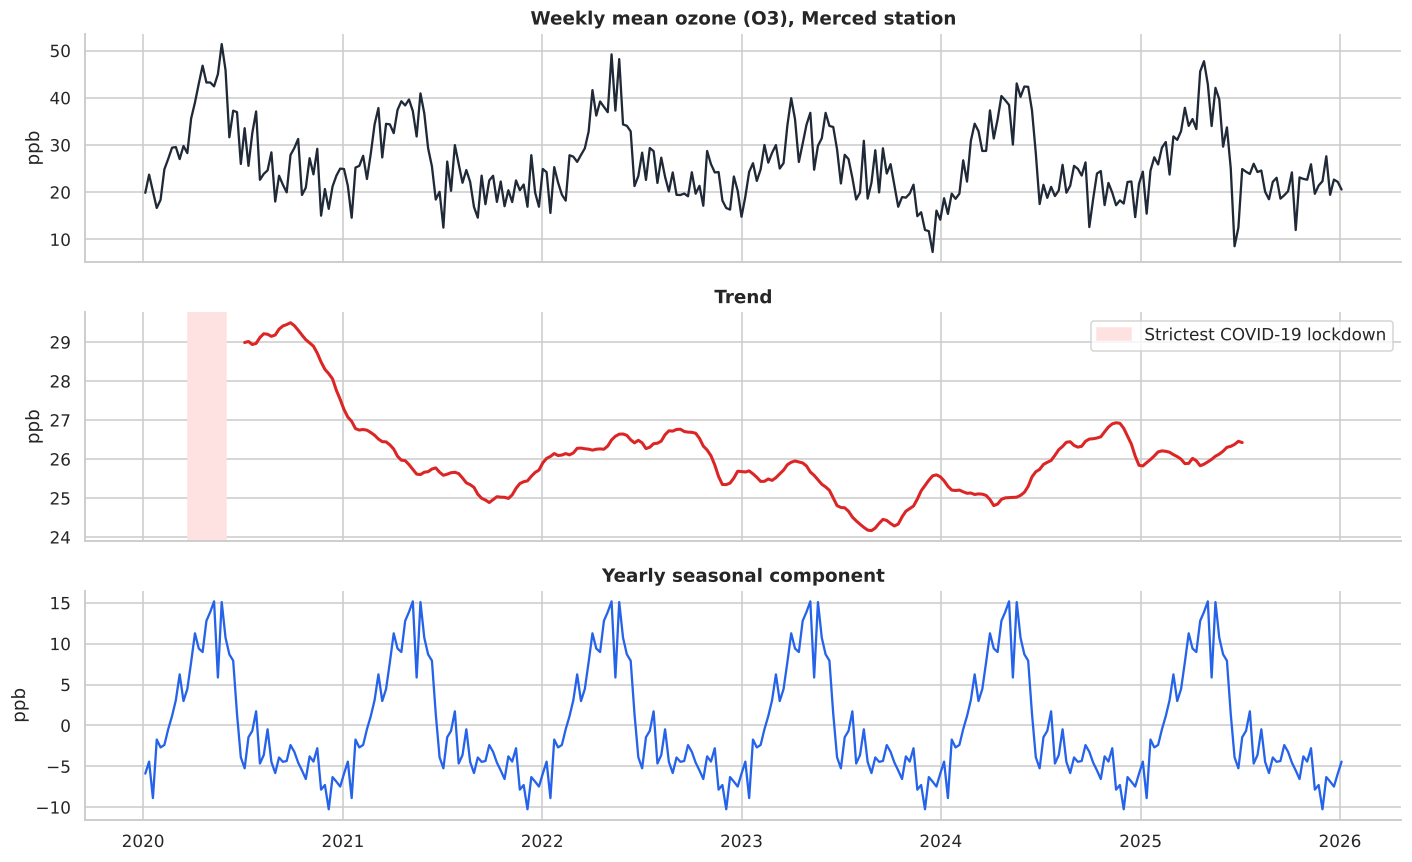

In [5]:
merced = df[df["station"] == "MER"].set_index("datetime").sort_index()
o3_weekly = merced["O3"].resample("W").mean()
decomposition = seasonal_decompose(o3_weekly, model="additive", period=52)

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].plot(decomposition.observed, color="#1F2937")
axes[0].set(title="Weekly mean ozone (O3), Merced station", ylabel="ppb")
axes[1].plot(decomposition.trend, color="#DC2626", linewidth=2)
axes[1].axvspan(pd.Timestamp("2020-03-23"), pd.Timestamp("2020-06-01"), color="#FEE2E2",
                label="Strictest COVID-19 lockdown")
axes[1].set(title="Trend", ylabel="ppb")
axes[1].legend(loc="upper right")
axes[2].plot(decomposition.seasonal, color="#2563EB")
axes[2].set(title="Yearly seasonal component", ylabel="ppb")
fig.tight_layout()
save_fig(fig, "02_o3_decomposition")
plt.show()

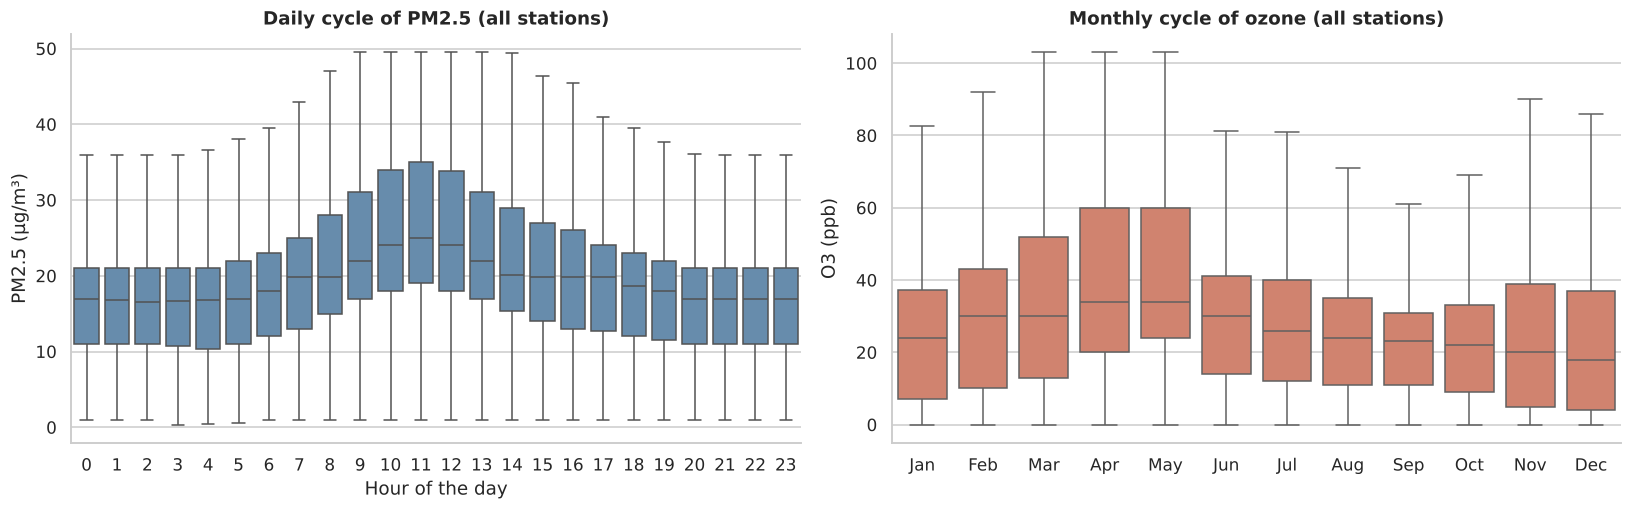

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
sns.boxplot(data=df, x=df["datetime"].dt.hour, y="PM25", color="#5B8DB8", showfliers=False, ax=ax1)
ax1.set(title="Daily cycle of PM2.5 (all stations)", xlabel="Hour of the day",
        ylabel=f"PM2.5 ({UNITS['PM25']})")
sns.boxplot(data=df, x=df["datetime"].dt.month, y="O3", color="#E07A5F", showfliers=False, ax=ax2)
ax2.set(title="Monthly cycle of ozone (all stations)", xlabel="", ylabel=f"O3 ({UNITS['O3']})")
ax2.set_xticks(range(12), MONTHS)
fig.tight_layout()
save_fig(fig, "02_daily_and_monthly_cycles")
plt.show()

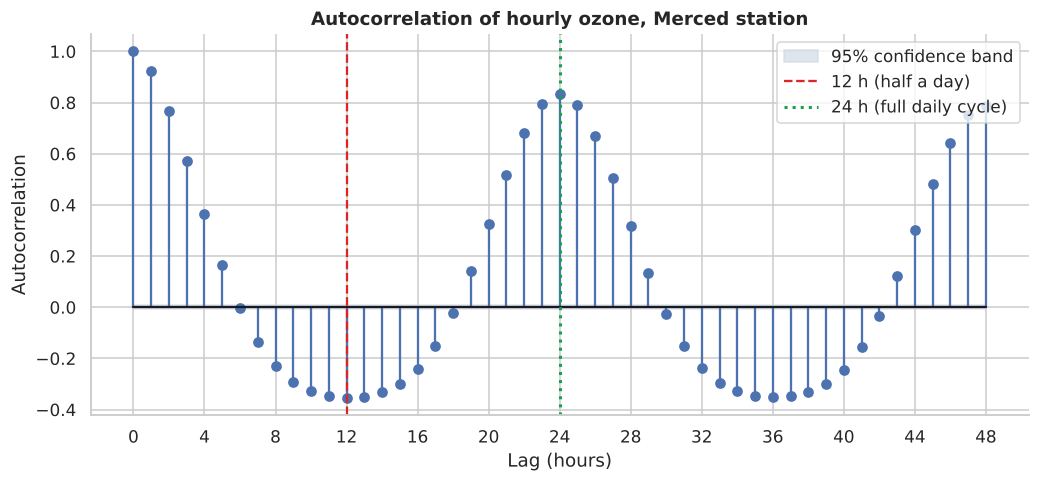

In [7]:
lags = 48
o3_acf = acf(merced["O3"], nlags=lags)
confidence = 1.96 / np.sqrt(len(merced))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stem(range(lags + 1), o3_acf, basefmt="k-")
ax.fill_between(range(lags + 1), -confidence, confidence, color="#CBD5E1", alpha=0.6,
                label="95% confidence band")
ax.axvline(12, color="#DC2626", linestyle="--", label="12 h (half a day)")
ax.axvline(24, color="#16A34A", linestyle=":", linewidth=2, label="24 h (full daily cycle)")
ax.set(title="Autocorrelation of hourly ozone, Merced station", xlabel="Lag (hours)",
       ylabel="Autocorrelation", xticks=range(0, lags + 1, 4))
ax.legend(loc="upper right")
save_fig(fig, "02_o3_autocorrelation")
plt.show()

* The trend is highest in 2020 and then settles between 24 and 27 ppb. Higher ozone during the
  COVID-19 lockdown is consistent with lower traffic emissions: less fresh NO is available to
  consume ozone. (The 52-week moving window has no values for the first and last half-year, so the
  trend line starts after the strictest lockdown period.)
* Ozone has a clear yearly cycle that peaks in spring (the warm, dry season), and PM2.5 has a
  daily cycle that peaks in the late morning (10 a.m. to 1 p.m.).
* The autocorrelation of ozone is strongly negative at about 12 hours and returns to a positive
  peak at **24 hours**: the dominant signal is the daily cycle. A **24-hour window** therefore
  gives the model one full cycle of context.

## 4. Scenario labels with K-Means

Pollutants are standardized and K-Means (k = 4) is fitted on the training period. Every hour of
every split is then assigned to its nearest centroid, and the scenarios are named from the
centroids exactly as in notebook 01.

In [8]:
scaler = StandardScaler().fit(df.loc[is_train, MODEL_FEATURES])
X_scaled = pd.DataFrame(scaler.transform(df[MODEL_FEATURES]), columns=MODEL_FEATURES, index=df.index)

kmeans = clustering.fit_kmeans(X_scaled[is_train].to_numpy(), n_clusters=4)
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=MODEL_FEATURES)
names = clustering.name_scenarios(centroids)

scenario_code = {name: i for i, name in enumerate(SCENARIO_ORDER)}
df["scenario"] = pd.Series(kmeans.predict(X_scaled.to_numpy()), index=df.index).map(names)
df["target"] = df["scenario"].map(scenario_code)

centroids.rename(index=names).loc[SCENARIO_ORDER].round(2)

,CO,NO,NO2,O3,SO2,PM10,PM25
Clean air,-0.80,-0.64,-0.85,0.02,-0.69,-0.89,-0.89
Moderate urban,0.08,0.08,0.24,-0.39,0.05,-0.12,-0.10
Ozone peak,-0.30,-0.60,-0.37,1.57,0.38,0.83,0.85
High pollution,1.74,1.75,1.52,-0.79,0.84,1.15,1.10


In [9]:
share = pd.crosstab(df["split"], df["scenario"], normalize="index").loc[
    ["train", "validation", "test"], SCENARIO_ORDER] * 100
share.round(1)

scenario,Clean air,Moderate urban,Ozone peak,High pollution
split,,,,
train,30.5,37.6,16.7,15.2
validation,29.7,34.8,19.1,16.4
test,30.2,34.1,19.2,16.6


## 5. Sequences

Each sample is a window of the last 24 hours of the 7 standardized pollutants at one station,
and its label is the scenario of the following hour. Windows are built per station so that
no window mixes two stations, and each sample is assigned to a split by the time of the hour
it predicts.

In [10]:
sequence_input = pd.concat([df[["datetime", "station", "target"]], X_scaled], axis=1)
X, y, target_time, station = make_sequences(sequence_input, MODEL_FEATURES, "target", LOOK_BACK)

# The scenario at time t (the last hour of each window) is needed for the persistence baseline.
sequence_input["target_now"] = sequence_input.groupby("station")["target"].shift(1)
_, y_current, current_time, _ = make_sequences(sequence_input, MODEL_FEATURES[:1], "target_now", LOOK_BACK)
assert (current_time == target_time).all()
y_current = y_current.astype(int)

target_year = (target_time - pd.Timedelta(hours=1)).year
splits = {
    "train": np.asarray(target_year <= 2023),
    "validation": np.asarray(target_year == 2024),
    "test": np.asarray(target_year == 2025),
}
X_train, y_train = X[splits["train"]], y[splits["train"]]
X_val, y_val = X[splits["validation"]], y[splits["validation"]]
X_test, y_test = X[splits["test"]], y[splits["test"]]

pd.DataFrame({name: {"samples": mask.sum()} for name, mask in splits.items()}).T.assign(
    window_shape=f"{LOOK_BACK} hours x {len(MODEL_FEATURES)} pollutants"
)

,samples,window_shape
train,245280,24 hours x 7 pollutants
validation,61474,24 hours x 7 pollutants
test,61320,24 hours x 7 pollutants


## 6. Baselines

A model is only useful if it beats simple alternatives:

* **Majority class**: always predict the most frequent scenario in training.
* **Persistence**: the next hour has the same scenario as the current hour.
* **Logistic regression (last hour)**: a linear model on the 7 pollutants of the current hour.
* **Logistic regression (24 h)**: a linear model on the full 24-hour window, flattened.

In [11]:
results = {}


def evaluate(name, y_true, y_pred):
    results[name] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }


majority = np.bincount(y_train).argmax()
evaluate("Majority class", y_test, np.full_like(y_test, majority))
evaluate("Persistence", y_test, y_current[splits["test"]])

logreg_last = LogisticRegression(max_iter=2000).fit(X_train[:, -1, :], y_train)
evaluate("Logistic regression (last hour)", y_test, logreg_last.predict(X_test[:, -1, :]))

logreg_window = LogisticRegression(max_iter=2000).fit(X_train.reshape(len(X_train), -1), y_train)
evaluate("Logistic regression (24 h)", y_test, logreg_window.predict(X_test.reshape(len(X_test), -1)))

pd.DataFrame(results).T

,accuracy,macro_f1
Majority class,0.341,0.127
Persistence,0.758,0.759
Logistic regression (last hour),0.768,0.771
Logistic regression (24 h),0.791,0.795


## 7. LSTM model

Architecture (unchanged from the original project): two stacked LSTM layers (128 and 64 units),
each followed by batch normalization and 30% dropout, a 32-unit dense layer and a 4-class
softmax output. Training uses Adam, balanced class weights, early stopping on the **validation**
loss and learning-rate reduction on plateaus.

In [12]:
import os  # noqa: E402

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # hide TensorFlow start-up logs

from tensorflow import keras  # noqa: E402

keras.utils.set_random_seed(RANDOM_STATE)

model = keras.Sequential(
    [
        keras.Input(shape=(LOOK_BACK, len(MODEL_FEATURES))),
        keras.layers.LSTM(128, return_sequences=True),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.3),
        keras.layers.LSTM(64),
        keras.layers.BatchNormalization(),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(len(SCENARIO_ORDER), activation="softmax"),
    ]
)
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 128)        │        69,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 24, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,020 (476.64 KB)

 Trainable params: 121,636 (475.14 KB)

 Non-trainable params: 384 (1.50 KB)

In [13]:
class_weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    class_weight=dict(enumerate(class_weights)),
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-4),
    ],
    verbose=2,
)

Epoch 1/30


959/959 - 106s - 111ms/step - accuracy: 0.7549 - loss: 0.5507 - val_accuracy: 0.7689 - val_loss: 0.5638 - learning_rate: 0.0010


Epoch 2/30


959/959 - 102s - 106ms/step - accuracy: 0.7873 - loss: 0.4733 - val_accuracy: 0.7870 - val_loss: 0.5213 - learning_rate: 0.0010


Epoch 3/30


...

959/959 - 98s - 103ms/step - accuracy: 0.7977 - loss: 0.4417 - val_accuracy: 0.7849 - val_loss: 0.5168 - learning_rate: 0.0010


Epoch 11/30


959/959 - 100s - 105ms/step - accuracy: 0.8004 - loss: 0.4361 - val_accuracy: 0.7882 - val_loss: 0.5112 - learning_rate: 5.0000e-04


Epoch 12/30


959/959 - 101s - 106ms/step - accuracy: 0.8008 - loss: 0.4344 - val_accuracy: 0.7886 - val_loss: 0.5116 - learning_rate: 5.0000e-04


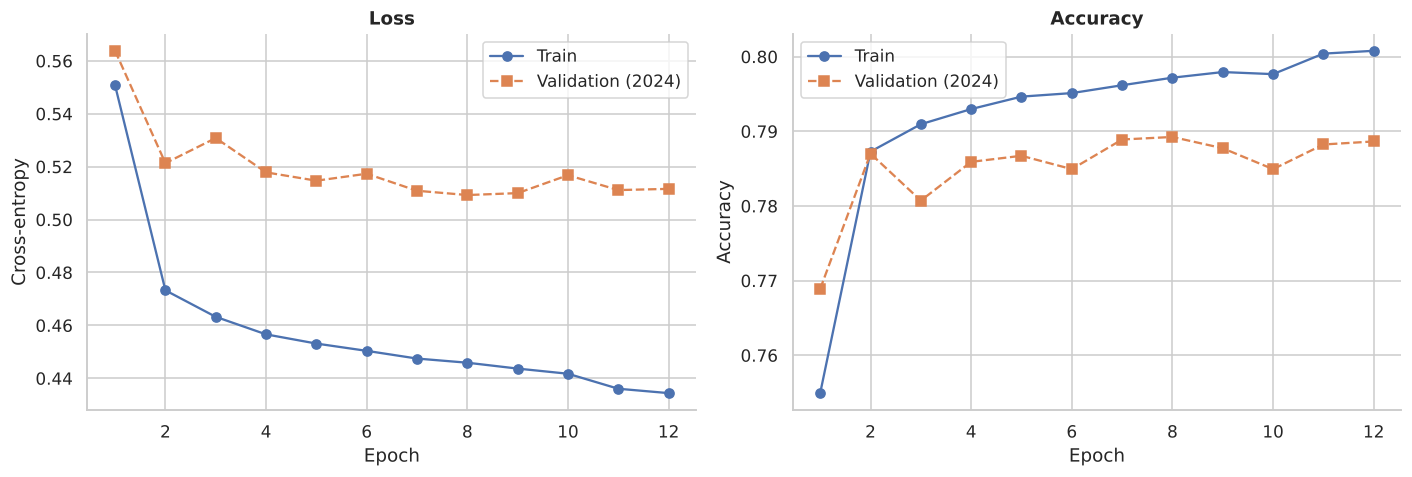

In [14]:
curves = pd.DataFrame(history.history)
curves.index += 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
curves[["loss", "val_loss"]].plot(ax=ax1, style=["o-", "s--"])
ax1.set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
ax1.legend(["Train", "Validation (2024)"])
curves[["accuracy", "val_accuracy"]].plot(ax=ax2, style=["o-", "s--"])
ax2.set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
ax2.legend(["Train", "Validation (2024)"])
fig.tight_layout()
save_fig(fig, "02_training_curves")
plt.show()

## 8. Evaluation on the test year (2025)

In [15]:
y_pred = model.predict(X_test, batch_size=1024, verbose=0).argmax(axis=1)
evaluate("LSTM (24 h)", y_test, y_pred)

comparison = pd.DataFrame(results).T.sort_values("macro_f1")
comparison

,accuracy,macro_f1
Majority class,0.341,0.127
Persistence,0.758,0.759
Logistic regression (last hour),0.768,0.771
LSTM (24 h),0.783,0.787
Logistic regression (24 h),0.791,0.795


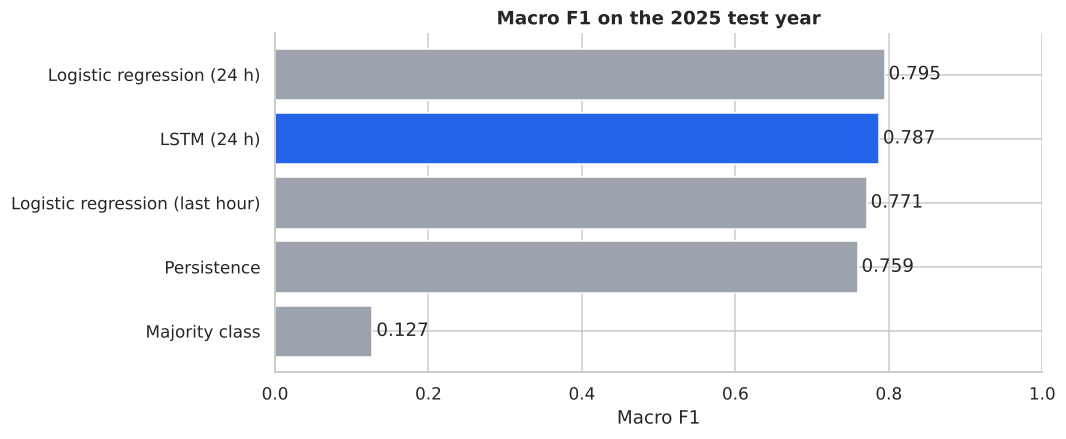

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#2563EB" if name.startswith("LSTM") else "#9CA3AF" for name in comparison.index]
ax.barh(comparison.index, comparison["macro_f1"], color=colors)
for i, v in enumerate(comparison["macro_f1"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set(title="Macro F1 on the 2025 test year", xlabel="Macro F1", xlim=(0, 1))
save_fig(fig, "02_model_comparison")
plt.show()

In [17]:
print(classification_report(y_test, y_pred, target_names=SCENARIO_ORDER, digits=3))

                precision    recall  f1-score   support

     Clean air      0.780     0.843     0.810     18488
Moderate urban      0.827     0.626     0.713     20884
    Ozone peak      0.781     0.900     0.836     11750
High pollution      0.731     0.859     0.790     10198

      accuracy                          0.783     61320
     macro avg      0.780     0.807     0.787     61320
  weighted avg      0.788     0.783     0.779     61320



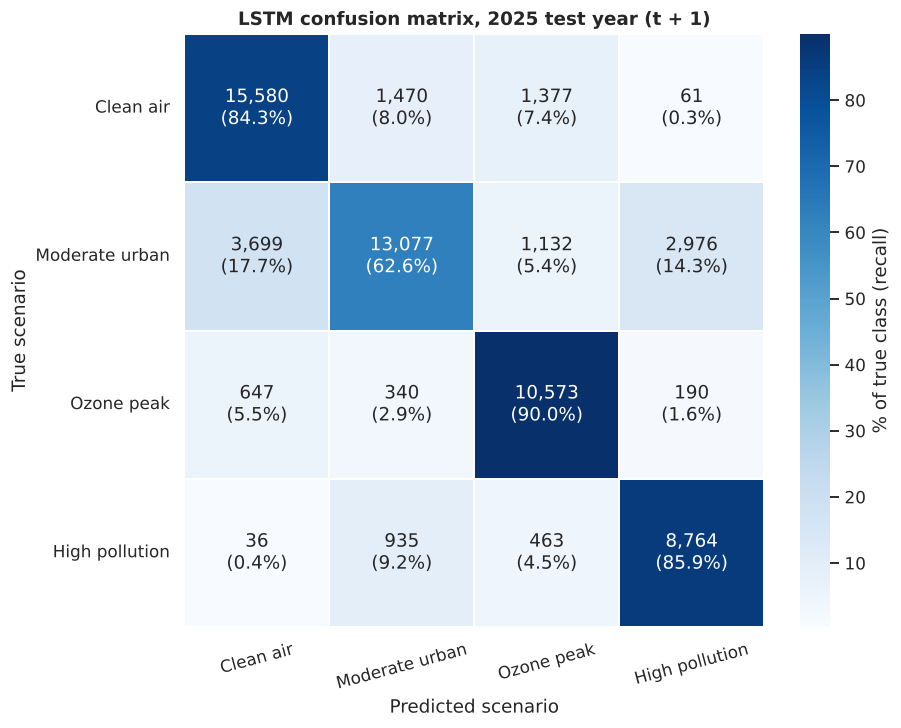

In [18]:
cm = confusion_matrix(y_test, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = np.array([[f"{n:,}\n({p:.1f}%)" for n, p in zip(row, prow, strict=True)]
                   for row, prow in zip(cm, cm_pct, strict=True)])

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm_pct, annot=labels, fmt="", cmap="Blues", linewidths=1, ax=ax,
            xticklabels=SCENARIO_ORDER, yticklabels=SCENARIO_ORDER,
            cbar_kws={"label": "% of true class (recall)"})
ax.set(title="LSTM confusion matrix, 2025 test year (t + 1)", xlabel="Predicted scenario",
       ylabel="True scenario")
ax.tick_params(axis="x", rotation=15)
ax.tick_params(axis="y", rotation=0)
save_fig(fig, "02_confusion_matrix")
plt.show()

### Where does the LSTM add value?

Persistence is right whenever the scenario does not change. The interesting hours are the ones
where it **does** change: the model has to anticipate the transition from the recent history.

In [19]:
changes = y_test != y_current[splits["test"]]
print(f"Share of test hours where the scenario changes: {changes.mean():.1%}")
print(f"LSTM accuracy on hours with a change:            {accuracy_score(y_test[changes], y_pred[changes]):.1%}")
print(f"LSTM accuracy on hours without a change:         {accuracy_score(y_test[~changes], y_pred[~changes]):.1%}")
print("Persistence accuracy on hours with a change:      0.0% (by definition)")

Share of test hours where the scenario changes: 24.2%
LSTM accuracy on hours with a change:            38.0%
LSTM accuracy on hours without a change:         91.1%
Persistence accuracy on hours with a change:      0.0% (by definition)


## 9. Conclusions

| Model | Accuracy | Macro F1 |
|---|---|---|
| Majority class | 0.341 | 0.127 |
| Persistence | 0.758 | 0.759 |
| Logistic regression (last hour) | 0.768 | 0.771 |
| **LSTM (24 h)** | **0.783** | **0.787** |
| Logistic regression (24 h) | 0.791 | 0.795 |

* The LSTM predicts the next-hour scenario of the 2025 test year with **78.3% accuracy and a
  macro F1 of 0.787**, clearly above the majority class and **2.8 points of macro F1 above
  persistence**. It anticipates 38% of the hours in which the scenario changes, which persistence
  can never do.
* **A logistic regression on the same 24-hour window performs slightly better (macro F1 0.795).**
  With this feature set, the next hour is largely a linear function of the recent history, and
  the extra capacity of the LSTM does not pay off. In production, the simpler model would be the
  better choice: it is faster to train, easier to explain and at least as accurate.
* *Moderate urban* is the hardest scenario (recall 0.63): it sits between the other three in
  pollutant space, so hours near its boundaries are often predicted as a neighbouring scenario.
  The balanced class weights favour recall on the smaller classes (*Ozone peak*, *High pollution*)
  at the cost of some accuracy on this one.
* **About the original version of this project.** The first version reported 77% accuracy, but
  its test set was the last 20% of the *stations* rather than the last period of time, the
  validation data used for early stopping was the test set itself, and the scaler and K-Means
  were fitted on all the data. This version fixes the three issues, so the numbers above are an
  honest estimate of performance on a future year.

**Next steps**

* Add calendar features (hour of day, weekday, month as cyclic encodings) and meteorological
  variables (temperature, wind, radiation), which drive ozone formation.
* Forecast further ahead (3, 6 or 24 hours), where persistence degrades faster and sequence
  models have more room to help.
* Try gradient-boosted trees on lagged features, a strong baseline for tabular time series.
* Forecast pollutant concentrations or the official air-quality index directly, instead of
  K-Means scenarios.